# Medical Appointment No-Show Prediction & Demand Forecasting
**Simple Python. Careful analytical decisions.**

This version follows the agreed 20 steps using direct pandas operations, short
cells, ordinary loops, and a few functions only where several models or periods
need the same calculation. There are no custom classes, source-code generators,
nested configuration systems, or separate utility modules.

Run the cells in order. `df` is the cleaned appointment table. `X_train` and
`y_train` hold classifier inputs and labels. `daily_counts` and
`specialty_counts` hold demand histories. Outputs are saved under `models/`
and `reports/`. The separate `app.py` reads those files after the notebook runs.

**Important execution status:** The original CSV was not available when this
rewrite was created. No model scores or conclusions from this new version have
been prefilled. Numerical results will appear only when you run the original
CSV through the notebook. Earlier-version scores do not belong to this rewrite.

**Requested goals:** no-show F1 > 0.70, ROC-AUC > 0.75, daily forecast MAPE < 20%,
and R² > 0.65. We calculate these on future test dates and clearly report failures.
Classification accuracy alone is not a substitute for these four requirements.

**Mac:** Install `requirements.txt` in a Python 3.12 virtual environment and open
this notebook in that kernel. **Colab:** upload the notebook, requirements, and
original CSV. If packages are missing, run `%pip install -r requirements.txt`
in a separate setup cell, restart the session, then run from Step 1.

## 1. Define the two prediction problems

**Objective:** Agree on what we predict before choosing algorithms.

**Workflow:** Separate appointment-level risk from daily booked demand and record the metric goals.

| Task | One prediction represents | Output | Proposed lead time |
|---|---|---|---|
| No-show prediction | One appointment | Probability that `no_show` is `yes` | One day before the appointment |
| Demand forecasting | One date, overall or by specialty | Booked appointments, including no-shows | Next seven calendar days |

Lead times are proposed operating choices. They must be confirmed with the
clinic. Without booking creation timestamps, we cannot reconstruct exactly
which appointments were already booked at a historical scoring time.

In [1]:
random_state = 42
forecast_days = 7

classification_goals = {"F1": 0.70, "ROC_AUC": 0.75}
forecast_goals = {"MAPE_percent": 20.0, "R2": 0.65}

print("Positive class: yes = missed appointment.")
print("Forecast target: booked appointment count, not attended patient count.")
print("Goals:", classification_goals, forecast_goals)

Positive class: yes = missed appointment.
Forecast target: booked appointment count, not attended patient count.
Goals: {'F1': 0.7, 'ROC_AUC': 0.75} {'MAPE_percent': 20.0, 'R2': 0.65}


**Code explanation:** Simple variables keep the few shared choices visible.

**Expected output:** Definitions and requested targets, not achieved scores.

**Validation:** The positive class must remain a missed appointment throughout.

**Professional insight:** Good project design starts with a decision the clinic needs to make, not with an algorithm.

## 2. Prepare the environment and folders

**Objective:** Make the work reproducible on Mac or Colab.

**Workflow:** Import the libraries and create two output folders.

In [2]:
from pathlib import Path
import json
import platform
import time
import os

# Keep temporary plotting files within the project folder.
os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import statsmodels
from IPython.display import display
from threadpoolctl import threadpool_limits

thread_limit = threadpool_limits(limits=2)
np.random.seed(random_state)
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 12)

models_folder = Path("models")
reports_folder = Path("reports")
models_folder.mkdir(exist_ok=True)
reports_folder.mkdir(exist_ok=True)

versions = {"Python": platform.python_version(), "pandas": pd.__version__,
            "numpy": np.__version__, "scikit-learn": sklearn.__version__,
            "statsmodels": statsmodels.__version__}
display(pd.DataFrame(versions.items(), columns=["Library", "Version"]))
(reports_folder / "versions.json").write_text(json.dumps(versions, indent=2))

,Library,Version
0,Python,3.12.14
1,pandas,2.2.3
2,numpy,2.3.3
3,scikit-learn,1.7.2
4,statsmodels,0.14.5


120

**Code explanation:** Path creates folders; display presents tables; thread limits keep training practical on a laptop.

**Expected output:** The installed package versions.

**Validation:** If an import fails, install requirements in this notebook's selected kernel and restart it.

**Professional insight:** A random seed helps repeatability, but matching data and package versions also matters.

## 3. Load the actual CSV and describe its columns

**Objective:** Inspect the source instead of guessing its structure.

**Workflow:** Read one explicit path, preview three rows, and build a data dictionary.

In [3]:
data_path = Path("Medical_appointment_data(1).csv")
# On Mac you can instead use Path.home() / "Downloads" / data_path.name.

if not data_path.is_file():
    raise FileNotFoundError("Place the original CSV beside this notebook, or edit data_path.")

df_raw = pd.read_csv(data_path)
print(f"Rows: {df_raw.shape[0]:,}; columns: {df_raw.shape[1]}")
display(df_raw.head(3))
df_raw.info()

Rows: 109,593; columns: 26


,specialty,appointment_time,gender,no_show,disability,place,...,Hipertension,Diabetes,Alcoholism,Handcap,Scholarship,SMS_received
0,psychotherapy,17,F,yes,intellectual,Lake Marvinville,...,0,0,0,0,0,0
1,NaN,7,M,no,intellectual,ITAPEMA,...,0,0,0,0,0,0
2,speech therapy,16,M,no,intellectual,ITAJAÍ,...,0,0,0,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109593 entries, 0 to 109592
Data columns (total 26 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   specialty                    89466 non-null   object 
 1   appointment_time             109593 non-null  int64  
 2   gender                       109593 non-null  object 
 3   no_show                      109593 non-null  object 
 4   disability                   92992 non-null   object 
 5   place                        98054 non-null   object 
 6   appointment_shift            109593 non-null  object 
 7   age                          86633 non-null   float64
 8   under_12_years_old           109593 non-null  int64  
 9   over_60_years_old            109593 non-null  int64  
 10  patient_needs_companion      109593 non-null  int64  
 11  average_temp_day             107382 non-null  float64
 12  average_rain_day             107348 non-null  float64
 13 

In [4]:
column_meanings = {
    "specialty": "Recorded appointment specialty; abbreviations need confirmation",
    "appointment_time": "Recorded appointment hour",
    "gender": "Recorded gender code; I needs definition",
    "no_show": "yes = missed; no = attended",
    "disability": "Recorded disability category",
    "place": "Recorded location; many labels need verification",
    "appointment_shift": "Recorded morning or afternoon shift",
    "age": "Recorded age in years",
    "under_12_years_old": "Recorded binary age flag",
    "over_60_years_old": "Recorded binary age flag",
    "patient_needs_companion": "Recorded companion requirement",
    "average_temp_day": "Observed average temperature; confirm unit",
    "average_rain_day": "Observed average rain; confirm unit",
    "max_temp_day": "Observed maximum temperature; confirm unit",
    "max_rain_day": "Observed maximum rain; confirm unit",
    "rainy_day_before": "Recorded prior-day rain flag; confirm construction",
    "storm_day_before": "Recorded prior-day storm flag; confirm construction",
    "rain_intensity": "Recorded rain category",
    "heat_intensity": "Recorded temperature category",
    "appointment_date_continuous": "Continuous calendar; confirm original date mapping",
    "Hipertension": "Recorded hypertension flag",
    "Diabetes": "Recorded diabetes flag",
    "Alcoholism": "Recorded alcoholism flag",
    "Handcap": "Recorded binary disability-related flag; confirm definition",
    "Scholarship": "Recorded scholarship flag; confirm definition",
    "SMS_received": "Recorded SMS receipt; timing not supplied",
}
missing_columns = sorted(set(column_meanings) - set(df_raw.columns))
if missing_columns:
    raise ValueError(f"The source schema differs from the reviewed CSV: {missing_columns}")

data_dictionary = pd.DataFrame({
    "column": df_raw.columns,
    "type": df_raw.dtypes.astype(str).values,
    "missing_percent": df_raw.isna().mean().mul(100).round(2).values,
    "unique_values": df_raw.nunique().values,
    "meaning": [column_meanings.get(column, "Review extra field") for column in df_raw],
})
display(data_dictionary)
data_dictionary.to_csv(reports_folder / "data_dictionary.csv", index=False)

,column,type,missing_percent,unique_values,meaning
0,specialty,object,18.37,8,Recorded appointment specialty; abbreviations ...
1,appointment_time,int64,0.00,12,Recorded appointment hour
2,gender,object,0.00,3,Recorded gender code; I needs definition
3,no_show,object,0.00,2,yes = missed; no = attended
4,disability,object,15.15,3,Recorded disability category
5,place,object,10.53,26289,Recorded location; many labels need verification
6,appointment_shift,object,0.00,2,Recorded morning or afternoon shift
7,age,float64,20.95,92,Recorded age in years
8,under_12_years_old,int64,0.00,2,Recorded binary age flag
9,over_60_years_old,int64,0.00,2,Recorded binary age flag


**Code explanation:** df_raw stays unchanged. The expected names were established by inspecting the user's original file earlier.

**Expected output:** Actual shape, preview, types, and missingness. Results depend on the CSV you supply.

**Validation:** Check that no_show and the continuous appointment date exist; investigate unexpected codes.

**Professional insight:** Do not invent meanings or units for unfamiliar fields.

## 4. Audit data quality

**Objective:** Identify problems before making cleaning decisions.

**Workflow:** Check labels, dates, missingness, duplicates, age flags, and location variety.

In [5]:
print("Target labels:")
display(df_raw["no_show"].value_counts(dropna=False).to_frame("appointments"))
print("Identical full rows:", df_raw.duplicated().sum())
print("Distinct nonmissing locations:", df_raw["place"].nunique())
print("Whitespace-only disability entries:", df_raw["disability"].fillna("x").str.strip().eq("").sum())

dates_check = pd.to_datetime(df_raw["appointment_date_continuous"], errors="coerce")
if dates_check.isna().any():
    raise ValueError("Review missing or invalid appointment dates before continuing.")
if df_raw["no_show"].isna().any() or set(df_raw["no_show"].unique()) != {"yes", "no"}:
    raise ValueError("Review the target: only nonmissing yes/no labels are expected.")

known_age = df_raw["age"].notna()
under_12_conflicts = known_age & (df_raw["age"].lt(12) != df_raw["under_12_years_old"].eq(1))
over_60_conflicts = known_age & (df_raw["age"].gt(60) != df_raw["over_60_years_old"].eq(1))
print("Recorded age conflicts with strict under-12 flag:", under_12_conflicts.sum())
print("Recorded age conflicts with strict over-60 flag:", over_60_conflicts.sum())

Target labels:


,appointments
no_show,
no,74761
yes,34832


Identical full rows: 36
Distinct nonmissing locations: 26289
Whitespace-only disability entries: 419
Recorded age conflicts with strict under-12 flag: 5072
Recorded age conflicts with strict over-60 flag: 1479


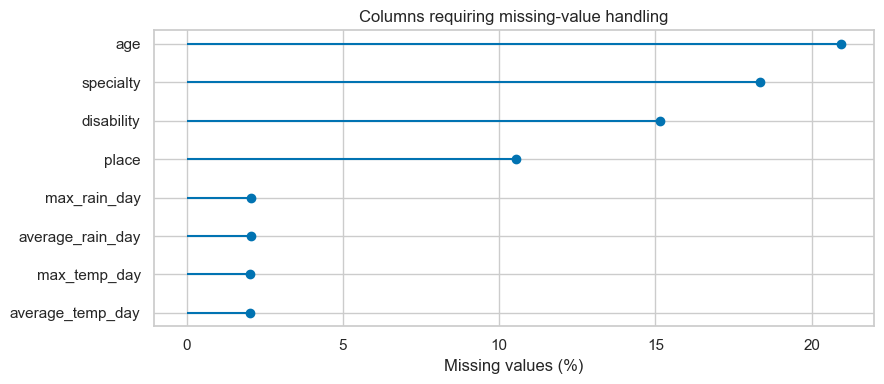

In [6]:
missing_percent = df_raw.isna().mean().mul(100).sort_values()
missing_percent = missing_percent[missing_percent > 0]
plt.figure(figsize=(9, 4))
plt.hlines(missing_percent.index, 0, missing_percent.values)
plt.scatter(missing_percent.values, missing_percent.index)
plt.xlabel("Missing values (%)")
plt.title("Columns requiring missing-value handling")
plt.tight_layout()
plt.show()

**Code explanation:** Each print answers a specific quality question; the lollipop plot avoids a large raw-data dump.

**Expected output:** Counts calculated from your file, with a missingness chart.

**Validation:** Invalid dates or labels stop the notebook. Review large location cardinality against the documented 13 cities.

**Professional insight:** Do not delete identical rows without appointment IDs: they could be separate real appointments.

## 5. Clean deterministically and preserve the source

**Objective:** Fix clear formatting issues without making unsupported replacements.

**Workflow:** Copy the data, strip text, convert dates and labels, and retain unresolved values.

In [7]:
df = df_raw.copy()
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip().replace("", np.nan)

df["appointment_date_continuous"] = pd.to_datetime(df["appointment_date_continuous"], errors="raise")
df["no_show_binary"] = df["no_show"].map({"yes": 1, "no": 0})
df = df.sort_values("appointment_date_continuous", kind="stable").reset_index(drop=True)

binary_columns = ["under_12_years_old", "over_60_years_old", "patient_needs_companion",
                  "Hipertension", "Diabetes", "Alcoholism", "Handcap", "Scholarship"]
for column in binary_columns:
    if not df[column].dropna().isin([0, 1]).all():
        raise ValueError(f"Unexpected nonbinary values in {column}.")
if not df["age"].dropna().between(0, 120).all():
    raise ValueError("Review ages outside the configured 0–120 quality range.")
if not df["appointment_time"].between(0, 23).all() or not df["appointment_time"].eq(df["appointment_time"].round()).all():
    raise ValueError("Appointment hours must be whole numbers from 0 to 23.")
assert len(df) == len(df_raw)
assert df["no_show_binary"].notna().all()
print(f"Cleaned rows: {len(df):,}; no-show rate: {df['no_show_binary'].mean():.2%}")

Cleaned rows: 109,593; no-show rate: 31.78%


**Code explanation:** The code fixes text formatting and creates a numeric target. It does not impute using the full data.

**Expected output:** The retained row count and actual no-show rate.

**Validation:** The raw table must remain intact. Row count must not change.

**Professional insight:** Retain conflicting age flags until their definitions are resolved. Exclude uncertain locations from predictive modeling rather than fabricating city mappings.

## 6. Explore no-show behavior

**Objective:** Describe useful patterns without using future test outcomes to guide model design.

**Workflow:** Use only the earliest 70% of dates for exploratory plots and show group sizes.

,no_show_rate,appointments
specialty,,
pedagogo,0.163,2613
enf,0.208,1220
occupational therapy,0.241,8266
assist,0.276,468
speech therapy,0.280,16292
psychotherapy,0.326,20957
physiotherapy,0.344,15266
Unknown,0.409,14721
sem especialidade,0.534,221


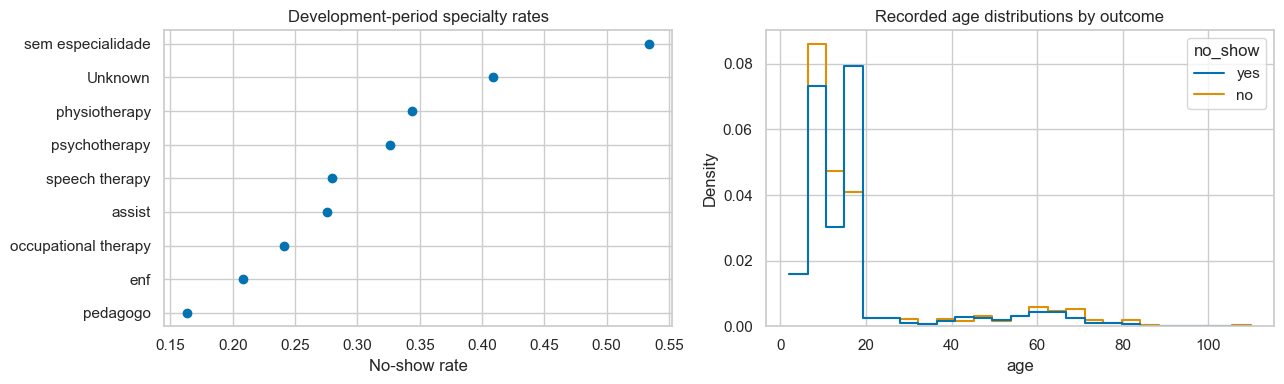

In [8]:
all_dates = pd.DatetimeIndex(df["appointment_date_continuous"].unique()).sort_values()
train_end = int(len(all_dates) * 0.70)
eda = df[df["appointment_date_continuous"].isin(all_dates[:train_end])].copy()

specialty_rates = eda.groupby(eda["specialty"].fillna("Unknown"))["no_show_binary"].agg(["mean", "size"])
specialty_rates = specialty_rates.sort_values("mean")
display(specialty_rates.rename(columns={"mean": "no_show_rate", "size": "appointments"}).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(specialty_rates["mean"], specialty_rates.index)
axes[0].set(xlabel="No-show rate", title="Development-period specialty rates")
sns.histplot(data=eda, x="age", hue="no_show", bins=25, stat="density",
             common_norm=False, element="step", fill=False, ax=axes[1])
axes[1].set_title("Recorded age distributions by outcome")
plt.tight_layout()
plt.show()

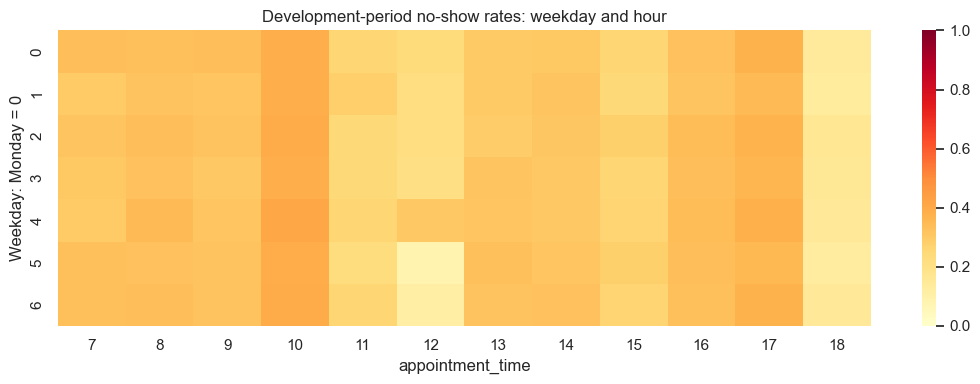

In [9]:
eda["weekday"] = eda["appointment_date_continuous"].dt.dayofweek
hourly_rates = eda.pivot_table(index="weekday", columns="appointment_time", values="no_show_binary", aggfunc="mean")
plt.figure(figsize=(11, 4))
sns.heatmap(hourly_rates, cmap="YlOrRd", vmin=0, vmax=1)
plt.title("Development-period no-show rates: weekday and hour")
plt.ylabel("Weekday: Monday = 0")
plt.tight_layout()
plt.show()

**Code explanation:** eda is deliberately limited to development dates. Density plots compare shapes even when class sizes differ.

**Expected output:** Rates, sample sizes, age histograms, and a weekday/hour heatmap.

**Validation:** Small groups need caution; an association is not a cause.

**Professional insight:** An impressive-looking full-data chart can still encourage test-set-driven decisions. Keep exploratory choices on development history.

## 7. Explore daily demand

**Objective:** Check the calendar and the variability a forecasting model must handle.

**Workflow:** Count bookings per day and inspect the development trend, weekday distributions, and autocorrelation.

Date range: 2020-01-01 to 2021-05-12
Calendar days: 498


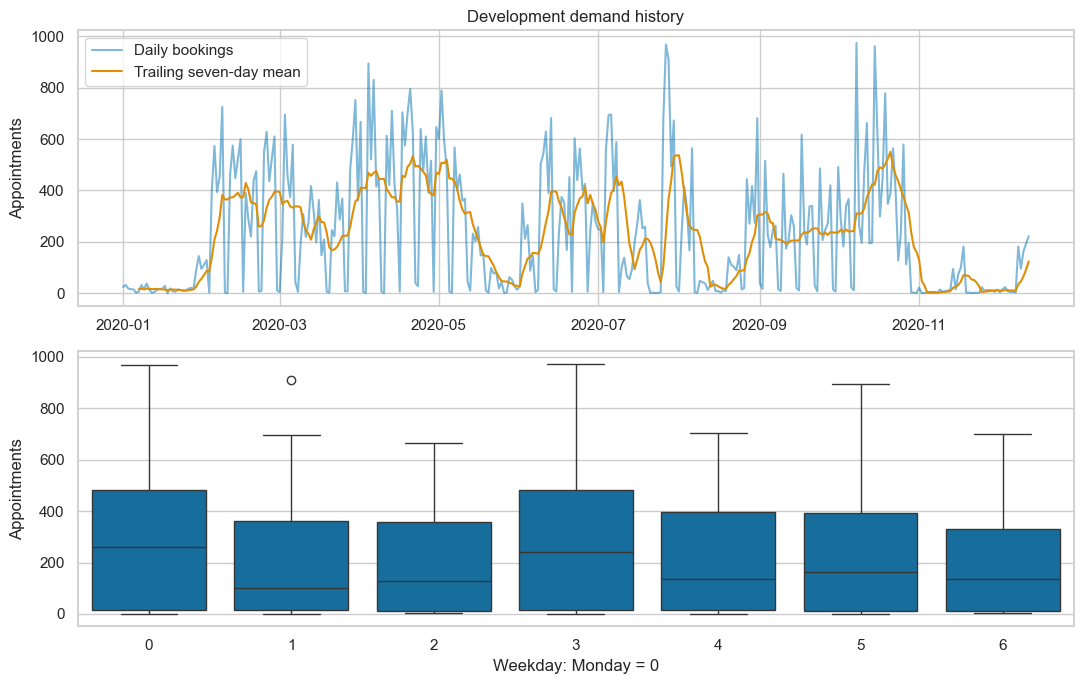

In [10]:
daily_counts = df.groupby("appointment_date_continuous").size().astype(float).asfreq("D")
if daily_counts.isna().any():
    raise ValueError("Missing calendar days need review; do not automatically treat them as zero demand.")
print("Date range:", daily_counts.index.min().date(), "to", daily_counts.index.max().date())
print("Calendar days:", len(daily_counts))
early_counts = daily_counts.loc[:all_dates[train_end - 1]]

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
axes[0].plot(early_counts, alpha=0.5, label="Daily bookings")
axes[0].plot(early_counts.rolling(7).mean(), label="Trailing seven-day mean")
axes[0].set(ylabel="Appointments", title="Development demand history")
axes[0].legend()
weekday_counts = pd.DataFrame({"count": early_counts, "weekday": early_counts.index.dayofweek})
sns.boxplot(data=weekday_counts, x="weekday", y="count", ax=axes[1])
axes[1].set(xlabel="Weekday: Monday = 0", ylabel="Appointments")
plt.tight_layout()
plt.show()

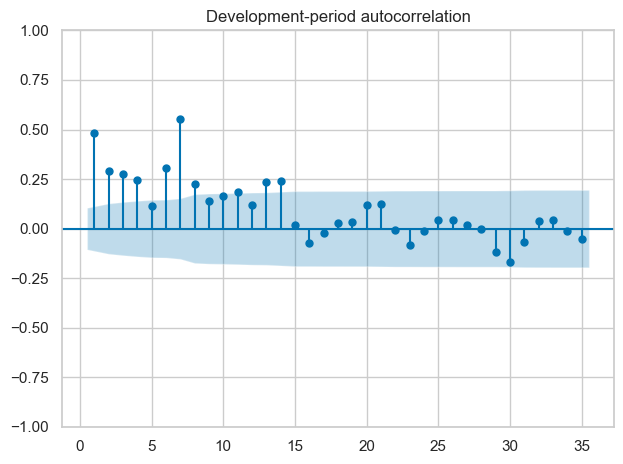

In [11]:
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(early_counts, lags=min(35, len(early_counts) // 3), zero=False)
plt.title("Development-period autocorrelation")
plt.tight_layout()
plt.show()

**Code explanation:** Daily bookings include attended and missed appointments. asfreq makes missing calendar dates visible.

**Expected output:** The actual date range and demand charts.

**Validation:** Missing dates trigger review rather than unsupported zero-filling.

**Professional insight:** Confirm how the continuous calendar was created. About 16 months of possibly remapped dates cannot establish reliable annual seasonality.

## 8. Decide which information is available at prediction time

**Objective:** Prevent leakage from information that arrives too late.

**Workflow:** Document included and excluded feature groups.

In [12]:
feature_decisions = pd.DataFrame([
    ["Demographics, health, specialty, shift and hour", "Include", "Assumed known before scoring; verify with the clinic"],
    ["Calendar features", "Include cautiously", "Requested date is known, but original calendar mapping needs checking"],
    ["Observed weather and weather-derived categories", "Exclude", "No historical forecast-weather inputs are supplied"],
    ["Previous-day rain/storm flags", "Exclude", "Construction and availability at scoring time are unconfirmed"],
    ["SMS_received", "Exclude", "Receipt timestamp relative to scoring is absent"],
    ["place", "Exclude", "Many city labels are unverified"],
    ["Patient history and booking lead time", "Unavailable", "No patient ID or booking timestamp"],
], columns=["Information", "Decision", "Reason"])
display(feature_decisions)
feature_decisions.to_csv(reports_folder / "feature_decisions.csv", index=False)

,Information,Decision,Reason
0,"Demographics, health, specialty, shift and hour",Include,Assumed known before scoring; verify with the ...
1,Calendar features,Include cautiously,"Requested date is known, but original calendar..."
2,Observed weather and weather-derived categories,Exclude,No historical forecast-weather inputs are supp...
3,Previous-day rain/storm flags,Exclude,Construction and availability at scoring time ...
4,SMS_received,Exclude,Receipt timestamp relative to scoring is absent
5,place,Exclude,Many city labels are unverified
6,Patient history and booking lead time,Unavailable,No patient ID or booking timestamp


**Code explanation:** A small table makes model scope explicit before training.

**Expected output:** A feature-availability decision table.

**Validation:** The later feature matrix must match these decisions.

**Professional insight:** Adding unavailable information may raise a retrospective score while making the live model unusable.

## 9. Create chronological classifier splits

**Objective:** Keep model selection, calibration, threshold tuning, and final testing separate.

**Workflow:** Fit on the earliest 70% of dates; divide the next 15% into three roles; reserve the final 15%.

In [13]:
validation_end = int(len(all_dates) * 0.85)
validation_dates = all_dates[train_end:validation_end]
first_cut = len(validation_dates) // 3
second_cut = 2 * len(validation_dates) // 3

train_dates = all_dates[:train_end]
selection_dates = validation_dates[:first_cut]
calibration_dates = validation_dates[first_cut:second_cut]
threshold_dates = validation_dates[second_cut:]
test_dates = all_dates[validation_end:]

classifier_splits = pd.DataFrame([
    ["Train", train_dates.min(), train_dates.max(), len(train_dates)],
    ["Model selection", selection_dates.min(), selection_dates.max(), len(selection_dates)],
    ["Probability calibration", calibration_dates.min(), calibration_dates.max(), len(calibration_dates)],
    ["Threshold tuning", threshold_dates.min(), threshold_dates.max(), len(threshold_dates)],
    ["Final test", test_dates.min(), test_dates.max(), len(test_dates)],
], columns=["Purpose", "First date", "Last date", "Days"])
assert classifier_splits["Days"].gt(0).all()
assert all(classifier_splits["Last date"].iloc[:-1].values < classifier_splits["First date"].iloc[1:].values)
display(classifier_splits)
classifier_splits.to_csv(reports_folder / "classifier_splits.csv", index=False)

,Purpose,First date,Last date,Days
0,Train,2020-01-01,2020-12-13,348
1,Model selection,2020-12-14,2021-01-07,25
2,Probability calibration,2021-01-08,2021-02-01,25
3,Threshold tuning,2021-02-02,2021-02-26,25
4,Final test,2021-02-27,2021-05-12,75


**Code explanation:** Each role gets entire dates, so one date cannot appear in both fitting and evaluation.

**Expected output:** Five date ranges. Their sizes depend on the supplied file.

**Validation:** Every range must be nonempty and strictly earlier than the next range.

**Professional insight:** Without patient IDs, this validates future dates but cannot establish patient-level independence.

## 10. Define training-only preprocessing

**Objective:** Handle missing values and categorical inputs without looking at future data.

**Workflow:** Use standard scikit-learn pipelines with numeric imputation and one-hot encoding.

In [14]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_columns = ["appointment_time", "age"] + binary_columns + ["weekday", "month"]
category_columns = ["specialty", "gender", "disability", "appointment_shift"]

numeric_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])
category_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessing = ColumnTransformer([
    ("numeric", numeric_steps, numeric_columns),
    ("category", category_steps, category_columns),
])
print("Preprocessing is defined but has not been fitted.")

Preprocessing is defined but has not been fitted.


**Code explanation:** A Pipeline is a library object, not a custom framework. It keeps fitted imputation/encoding with the model for the app.

**Expected output:** A message confirming that nothing has been fitted yet.

**Validation:** Do not fit preprocessing on the full table. Unknown categories will be handled at prediction time.

**Professional insight:** This small amount of structure prevents a common and serious beginner mistake: fitting cleaning statistics before splitting.

## 11. Build classification features and reuse the splits

**Objective:** Create a clear input table with no outcome or future observations.

**Workflow:** Add two known calendar features, choose explicit columns, and extract each date partition.

In [15]:
df["weekday"] = df["appointment_date_continuous"].dt.dayofweek
df["month"] = df["appointment_date_continuous"].dt.month
X = df[numeric_columns + category_columns].copy()
y = df["no_show_binary"].astype(int)

train_mask = df["appointment_date_continuous"].isin(train_dates)
selection_mask = df["appointment_date_continuous"].isin(selection_dates)
calibration_mask = df["appointment_date_continuous"].isin(calibration_dates)
threshold_mask = df["appointment_date_continuous"].isin(threshold_dates)
test_mask = df["appointment_date_continuous"].isin(test_dates)

X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_selection, y_selection = X.loc[selection_mask], y.loc[selection_mask]
X_calibration, y_calibration = X.loc[calibration_mask], y.loc[calibration_mask]
X_threshold, y_threshold = X.loc[threshold_mask], y.loc[threshold_mask]
X_test, y_test = X.loc[test_mask], y.loc[test_mask]

assert (train_mask.astype(int) + selection_mask + calibration_mask + threshold_mask + test_mask).eq(1).all()
assert not {"no_show", "no_show_binary", "SMS_received", "place"}.intersection(X.columns)
for labels in [y_train, y_selection, y_calibration, y_threshold, y_test]:
    assert labels.nunique() == 2, "Every classifier period needs both classes."
display(X_train.head(3))
print("Training shape:", X_train.shape, "No-show rate:", round(y_train.mean(), 3))

,appointment_time,age,under_12_years_old,over_60_years_old,patient_needs_companion,Hipertension,...,weekday,month,specialty,gender,disability,appointment_shift
0,17,9.0,1,0,1,0,...,2,1,psychotherapy,F,intellectual,afternoon
1,7,11.0,1,0,1,0,...,2,1,NaN,M,intellectual,morning
2,16,8.0,1,0,1,0,...,2,1,speech therapy,M,intellectual,afternoon


Training shape: (80024, 16) No-show rate: 0.32


**Code explanation:** X holds inputs and y holds the outcome. All variables keep their indices aligned.

**Expected output:** An actual feature preview and training shape.

**Validation:** Every appointment must belong to exactly one period; target and excluded columns must stay out of X.

**Professional insight:** We intentionally keep only simple calendar features. More feature engineering is worthwhile only when validated on development data.

## 12. Compare three classification algorithms

**Objective:** Compare simple and nonlinear models using the same inputs and date boundaries.

**Workflow:** Train logistic regression, random forest, and two gradient-boosting settings; compare on model-selection data.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (f1_score, roc_auc_score, average_precision_score,
                             precision_score, recall_score, accuracy_score, brier_score_loss)

# This function avoids repeating the exact metric calculation in several steps.
def classification_scores(actual, probability, threshold=0.5):
    predicted = np.asarray(probability) >= threshold
    return {"F1": f1_score(actual, predicted, zero_division=0),
            "ROC_AUC": roc_auc_score(actual, probability),
            "PR_AUC": average_precision_score(actual, probability),
            "Precision": precision_score(actual, predicted, zero_division=0),
            "Recall": recall_score(actual, predicted, zero_division=0),
            "Accuracy": accuracy_score(actual, predicted),
            "Brier": brier_score_loss(actual, probability)}

classifiers = {
    "Logistic regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=random_state),
    "Random forest": RandomForestClassifier(n_estimators=150, max_depth=16, min_samples_leaf=10, class_weight="balanced_subsample", n_jobs=2, random_state=random_state),
    "Gradient boosting - small": HistGradientBoostingClassifier(max_iter=200, max_leaf_nodes=7, l2_regularization=10, early_stopping=False, random_state=random_state),
    "Gradient boosting - medium": HistGradientBoostingClassifier(max_iter=250, max_leaf_nodes=15, l2_regularization=10, early_stopping=False, random_state=random_state),
}

In [17]:
fitted_classifiers = {}
selection_rows = []
for name, classifier in classifiers.items():
    print("Training:", name)
    model = Pipeline([("preprocessing", clone(preprocessing)), ("classifier", classifier)])
    model.fit(X_train, y_train)
    probability = model.predict_proba(X_selection)[:, 1]
    fitted_classifiers[name] = model
    selection_rows.append({"Model": name, **classification_scores(y_selection, probability)})

selection_scores = pd.DataFrame(selection_rows).sort_values("PR_AUC", ascending=False)
display(selection_scores.round(4))
selection_scores.to_csv(reports_folder / "classifier_selection.csv", index=False)

Training: Logistic regression


Training: Random forest


Training: Gradient boosting - small


Training: Gradient boosting - medium


,Model,F1,ROC_AUC,PR_AUC,Precision,Recall,Accuracy,Brier
2,Gradient boosting - small,0.3134,0.6809,0.5062,0.5727,0.2158,0.6841,0.2032
3,Gradient boosting - medium,0.3597,0.6832,0.5027,0.5707,0.2626,0.6875,0.2023
1,Random forest,0.5205,0.6758,0.4911,0.4995,0.5434,0.6654,0.2246
0,Logistic regression,0.4593,0.6009,0.4333,0.4082,0.5251,0.5868,0.2423


**Code explanation:** The loop repeats genuine model fitting, not boilerplate infrastructure. Class weighting is used for logistic regression and random forest; unweighted boosting is another reasonable comparison at roughly 32% positives.

**Expected output:** Real selection-period metrics for at least three algorithms, including a small manual boosting comparison.

**Validation:** Each pipeline fits preprocessing on training rows only. No test scores are inspected here.

**Professional insight:** PR-AUC is used for selection because it emphasizes the no-show class. Resampling is not automatically necessary for this degree of imbalance.

## 13. Calibrate probabilities and choose a threshold

**Objective:** Turn the selected model into a risk score and a practical decision rule.

**Workflow:** Freeze the best selection model, fit a simple probability adjustment on later dates, and tune F1 on another later period.

In [18]:
best_name = selection_scores.iloc[0]["Model"]
best_classifier = fitted_classifiers[best_name]

# A one-input logistic model adjusts raw scores using separate later labels.
calibration_input = best_classifier.predict_proba(X_calibration)[:, [1]]
probability_adjustment = LogisticRegression(C=1000, max_iter=1000)
probability_adjustment.fit(calibration_input, y_calibration)

threshold_input = best_classifier.predict_proba(X_threshold)[:, [1]]
threshold_probabilities = probability_adjustment.predict_proba(threshold_input)[:, 1]

from sklearn.metrics import precision_recall_curve
precision, recall, thresholds = precision_recall_curve(y_threshold, threshold_probabilities)
f1_values = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
decision_threshold = float(thresholds[np.argmax(f1_values)])

print("Selected model:", best_name)
print("Validation-selected threshold:", round(decision_threshold, 4))
display(pd.DataFrame([classification_scores(y_threshold, threshold_probabilities, decision_threshold)]).round(4))
print(f"Appointments flagged on threshold-validation data: {(threshold_probabilities >= decision_threshold).mean():.1%}")

Selected model: Gradient boosting - small
Validation-selected threshold: 0.2549


,F1,ROC_AUC,PR_AUC,Precision,Recall,Accuracy,Brier
0,0.5224,0.6786,0.4791,0.4197,0.6917,0.606,0.1963


Appointments flagged on threshold-validation data: 51.3%


**Code explanation:** [:, [1]] keeps probabilities as a two-dimensional input for the adjustment model. The original classifier is not refitted during calibration. The threshold is chosen on separate dates.

**Expected output:** The selected model, adjusted validation scores, threshold, and flagged fraction.

**Validation:** Calibration and threshold labels must not come from training, selection, or test dates.

**Professional insight:** An F1-optimal threshold can create too many follow-ups. Choose a clinic contact budget before using the decision rule operationally.

## 14. Evaluate and explain the frozen classifier

**Objective:** Measure future performance honestly and show more than one metric.

**Workflow:** Calculate test scores, compare trivial baselines, inspect calibration and discrimination, then report importance and subgroup behavior.

In [19]:
raw_test_probabilities = best_classifier.predict_proba(X_test)[:, [1]]
test_probabilities = probability_adjustment.predict_proba(raw_test_probabilities)[:, 1]
final_classifier_scores = classification_scores(y_test, test_probabilities, decision_threshold)

baseline_probabilities = np.repeat(y_train.mean(), len(y_test))
classifier_test_table = pd.DataFrame([
    {"Model": best_name, **final_classifier_scores},
    {"Model": "Training-prevalence baseline", **classification_scores(y_test, baseline_probabilities)},
    {"Model": "Always flag no-show", **classification_scores(y_test, baseline_probabilities, threshold=0)},
])
display(classifier_test_table.round(4))
classifier_test_table.to_csv(reports_folder / "classification_test.csv", index=False)
print("This is the final test. Do not change the model or threshold based on these results.")

,Model,F1,ROC_AUC,PR_AUC,Precision,Recall,Accuracy,Brier
0,Gradient boosting - small,0.5171,0.6837,0.4875,0.4165,0.6819,0.6048,0.1943
1,Training-prevalence baseline,0.0000,0.5000,0.3104,0.0000,0.0000,0.6896,0.2141
2,Always flag no-show,0.4737,0.5000,0.3104,0.3104,1.0000,0.3104,0.2141


This is the final test. Do not change the model or threshold based on these results.


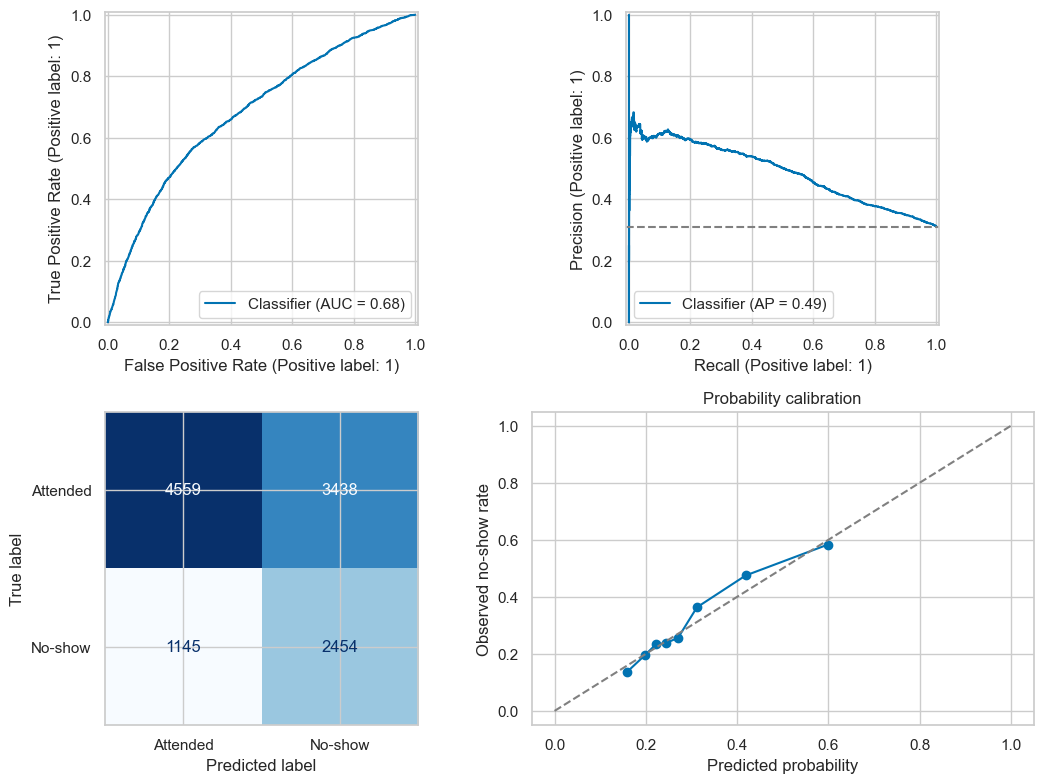

In [20]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
RocCurveDisplay.from_predictions(y_test, test_probabilities, ax=axes[0, 0])
PrecisionRecallDisplay.from_predictions(y_test, test_probabilities, ax=axes[0, 1])
axes[0, 1].axhline(y_test.mean(), linestyle="--", color="gray")
ConfusionMatrixDisplay.from_predictions(y_test, test_probabilities >= decision_threshold,
    display_labels=["Attended", "No-show"], ax=axes[1, 0], colorbar=False, cmap="Blues")
observed, predicted = calibration_curve(y_test, test_probabilities, n_bins=8, strategy="quantile")
axes[1, 1].plot(predicted, observed, "o-")
axes[1, 1].plot([0, 1], [0, 1], "--", color="gray")
axes[1, 1].set(xlabel="Predicted probability", ylabel="Observed no-show rate", title="Probability calibration")
plt.tight_layout()
plt.savefig(reports_folder / "classification_charts.png", dpi=150)
plt.show()

In [21]:
from sklearn.inspection import permutation_importance

sample = X_selection.sample(min(2000, len(X_selection)), random_state=random_state)
importance = permutation_importance(best_classifier, sample, y_selection.loc[sample.index],
                                   scoring="average_precision", n_repeats=3, random_state=random_state)
feature_importance = pd.DataFrame({"Feature": X.columns, "PR_AUC_drop": importance.importances_mean}).sort_values("PR_AUC_drop", ascending=False)
display(feature_importance.head(10).round(4))
feature_importance.to_csv(reports_folder / "feature_importance.csv", index=False)

subgroup_rows = []
for column in ["gender", "specialty"]:
    groups = df.loc[test_mask, column].fillna("Unknown")
    for value in groups.unique():
        mask = groups.eq(value).to_numpy()
        if mask.sum() >= 100 and y_test.iloc[mask].nunique() == 2:
            subgroup_rows.append({"Group": column, "Value": value, "Appointments": int(mask.sum()),
                                  **classification_scores(y_test.iloc[mask], test_probabilities[mask], decision_threshold)})
subgroup_scores = pd.DataFrame(subgroup_rows)
display(subgroup_scores.round(3))
subgroup_scores.to_csv(reports_folder / "classifier_subgroups.csv", index=False)

,Feature,PR_AUC_drop
1,age,0.1203
14,disability,0.0604
2,under_12_years_old,0.0258
0,appointment_time,0.0256
15,appointment_shift,0.0200
12,specialty,0.0169
3,over_60_years_old,0.0114
4,patient_needs_companion,0.0051
13,gender,0.0032
7,Alcoholism,0.0008


,Group,Value,Appointments,F1,ROC_AUC,PR_AUC,Precision,Recall,Accuracy,Brier
0,gender,F,2980,0.533,0.679,0.500,0.418,0.736,0.572,0.202
1,gender,M,8595,0.511,0.684,0.483,0.416,0.662,0.615,0.192
2,specialty,speech therapy,2377,0.472,0.666,0.453,0.460,0.486,0.699,0.185
3,specialty,pedagogo,375,0.112,0.577,0.208,0.156,0.088,0.789,0.129
4,specialty,Unknown,2088,0.581,0.656,0.548,0.432,0.884,0.485,0.223
5,specialty,occupational therapy,1207,0.372,0.649,0.399,0.424,0.331,0.742,0.165
6,specialty,psychotherapy,3027,0.515,0.667,0.490,0.401,0.720,0.568,0.200
7,specialty,enf,181,0.364,0.665,0.364,0.350,0.378,0.729,0.154
8,specialty,physiotherapy,2238,0.523,0.686,0.479,0.399,0.761,0.552,0.199


**Code explanation:** Baseline comparisons expose misleading majority-class accuracy. Feature importance is measured on selection data; the calibration chart checks the adjusted probabilities on test dates.

**Expected output:** Measured test tables, ROC/PR curves, confusion matrix, calibration plot, importance, and subgroup results.

**Validation:** Probabilities must be finite and between 0 and 1. Avoid strong conclusions for small groups.

**Professional insight:** Importance is association, not cause. Failed target scores remain failed; do not fix them by retuning on this test period.

## 15. Build daily specialty demand tables

**Objective:** Forecast booked demand without losing unknown specialties or confusing missing dates with zero demand.

**Workflow:** Aggregate specialty counts and create forecast training, selection, interval-calibration, and test periods.

In [22]:
specialty_counts = pd.crosstab(df["appointment_date_continuous"], df["specialty"].fillna("Unknown")).astype(float)
specialty_counts = specialty_counts.reindex(daily_counts.index, fill_value=0).asfreq("D")
assert np.allclose(specialty_counts.sum(axis=1), daily_counts)
assert specialty_counts.to_numpy().sum() == len(df)

forecast_test_start = len(daily_counts) - 56
forecast_validation_start = forecast_test_start - 56
forecast_interval_start = forecast_validation_start + 28
if forecast_validation_start < 112:
    raise ValueError("This evaluation needs at least 224 calendar days of history.")

demand_series = {"Overall": daily_counts}
for specialty in specialty_counts:
    demand_series[specialty] = specialty_counts[specialty]
display(specialty_counts.head(3))
print("Training ends:", daily_counts.index[forecast_validation_start - 1].date())
print("Selection dates:", daily_counts.index[forecast_validation_start].date(), "to", daily_counts.index[forecast_interval_start - 1].date())
print("Interval dates:", daily_counts.index[forecast_interval_start].date(), "to", daily_counts.index[forecast_test_start - 1].date())
print("Test dates:", daily_counts.index[forecast_test_start].date(), "to", daily_counts.index[-1].date())

specialty,Unknown,assist,enf,occupational therapy,pedagogo,physiotherapy,psychotherapy,sem especialidade,speech therapy
appointment_date_continuous,,,,,,,,,
2020-01-01,2.0,1.0,0.0,3.0,0.0,6.0,7.0,0.0,6.0
2020-01-02,3.0,0.0,0.0,4.0,3.0,7.0,12.0,0.0,4.0
2020-01-03,2.0,0.0,0.0,3.0,1.0,5.0,3.0,0.0,4.0


Training ends: 2021-01-20
Selection dates: 2021-01-21 to 2021-02-17
Interval dates: 2021-02-18 to 2021-03-17
Test dates: 2021-03-18 to 2021-05-12


**Code explanation:** Unknown specialties stay in the table. A zero within a date with observed appointments means no recorded bookings for that specialty.

**Expected output:** Reconciled daily counts and actual forecast evaluation dates.

**Validation:** The totals must equal all source appointments. If source capture is incomplete, zero assumptions need review.

**Professional insight:** A forecast count is not a staffing plan until appointment durations, specialist capacity, and service constraints are supplied.

## 16. Create forecast inputs known seven days ahead

**Objective:** Avoid using unseen actual counts inside a seven-day forecast.

**Workflow:** Use lags of at least seven days, shifted weekly averages, and known calendar fields.

In [23]:
# This short function is reused for training, validation, testing, and future inputs.
def forecast_features(series):
    features = pd.DataFrame(index=series.index)
    for lag in [7, 14, 21, 28]:
        features[f"lag_{lag}"] = series.shift(lag)
    features["past_week_mean"] = series.shift(7).rolling(7).mean()
    features["weekday"] = series.index.dayofweek
    features["month"] = series.index.month
    return features

training_demand = daily_counts.iloc[:forecast_validation_start]
display(forecast_features(training_demand).dropna().head(3))

# If today's count changes, today's input features must not change.
original = forecast_features(training_demand).iloc[-1]
changed_history = training_demand.copy()
changed_history.iloc[-1] += 10000
pd.testing.assert_series_equal(original, forecast_features(changed_history).iloc[-1])
print("Forecast input leakage check passed.")

,lag_7,lag_14,lag_21,lag_28,past_week_mean,weekday,month
appointment_date_continuous,,,,,,,
2020-01-29,15.0,17.0,32.0,25.0,13.571429,2,1
2020-01-30,13.0,17.0,17.0,33.0,13.000000,3,1
2020-01-31,11.0,29.0,38.0,18.0,10.428571,4,1


Forecast input leakage check passed.


**Code explanation:** For the next seven days, lag_7 always refers to a date already observed at the origin. shift(7).rolling(7) also stays entirely in known history.

**Expected output:** Seven transparent forecast features and a successful check.

**Validation:** The perturbation assertion must pass. Restrict this feature design to a maximum seven-day forecast.

**Professional insight:** Choosing inputs that are already known for the whole horizon removes the need for a complicated recursive prediction loop. It can trade recency for clarity; validation decides whether it helps.

## 17. Compare three forecast algorithms and a baseline

**Objective:** Evaluate the same seven-day task for every method.

**Workflow:** Use a few reusable functions to refit at each weekly origin; choose models on the first 28 validation days.

In [24]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

def fit_forecast(history, method, days=7):
    if not 1 <= days <= 7:
        raise ValueError("The supported forecast horizon is one to seven days.")
    history = history.astype(float).asfreq("D")
    if history.isna().any():
        raise ValueError("Forecast history contains missing calendar days.")

    if method == "Seasonal naive":
        model = None
        prediction = history.iloc[-7:].to_numpy()[:days]
    elif method == "Exponential smoothing":
        model = ExponentialSmoothing(history, trend="add", damped_trend=True,
            seasonal="add", seasonal_periods=7).fit(use_brute=False)
        prediction = model.forecast(days)
    elif method == "SARIMA":
        model = SARIMAX(history, order=(1, 0, 0), seasonal_order=(1, 0, 0, 7), trend="c").fit(disp=False, maxiter=150)
        prediction = model.forecast(days)
    elif method == "Gradient boosting":
        features = forecast_features(history)
        valid = features.notna().all(axis=1)
        model = HistGradientBoostingRegressor(loss="absolute_error", max_iter=150,
            max_leaf_nodes=7, min_samples_leaf=10, early_stopping=False, random_state=random_state)
        model.fit(features.loc[valid], history.loc[valid])
        future_dates = pd.date_range(history.index[-1] + pd.Timedelta(days=1), periods=days)
        extended = pd.concat([history, pd.Series(np.nan, index=future_dates)])
        prediction = model.predict(forecast_features(extended).loc[future_dates])
    else:
        raise ValueError(f"Unknown method: {method}")
    prediction = np.maximum(np.asarray(prediction, dtype=float), 0)
    if not np.isfinite(prediction).all():
        raise ValueError(f"Nonfinite forecasts from {method}.")
    return model, prediction

In [25]:
# One backtest function ensures that each candidate receives the same dates.
def forecast_backtest(series, start, stop, methods):
    rows = []
    for origin in range(start, stop, 7):
        history = series.iloc[:origin]
        actual = series.iloc[origin:min(origin + 7, stop)]
        for method in methods:
            model, prediction = fit_forecast(history, method, len(actual))
            for lead, (date, count, estimate) in enumerate(zip(actual.index, actual, prediction), start=1):
                rows.append({"date": date, "days_ahead": lead, "method": method,
                             "actual": float(count), "prediction": float(estimate)})
    return pd.DataFrame(rows)

def forecast_scores(results):
    actual = results["actual"].to_numpy()
    prediction = results["prediction"].to_numpy()
    nonzero = actual > 0
    total = np.abs(actual).sum()
    return {"MAE": mean_absolute_error(actual, prediction),
            "RMSE": np.sqrt(mean_squared_error(actual, prediction)),
            "MAPE_percent": 100 * np.abs((actual[nonzero] - prediction[nonzero]) / actual[nonzero]).mean() if nonzero.any() else np.nan,
            "WAPE_percent": 100 * np.abs(actual - prediction).sum() / total if total else np.nan,
            "R2": r2_score(actual, prediction) if np.var(actual) > 0 else np.nan,
            "Zero_actual_days": int((~nonzero).sum())}

In [26]:
forecast_methods = ["Seasonal naive", "Exponential smoothing", "SARIMA", "Gradient boosting"]
validation_frames = []
for specialty, history in demand_series.items():
    print("Comparing forecasts:", specialty)
    results = forecast_backtest(history, forecast_validation_start, forecast_test_start, forecast_methods)
    results["specialty"] = specialty
    validation_frames.append(results)
forecast_validation = pd.concat(validation_frames, ignore_index=True)

selection_cutoff = daily_counts.index[forecast_interval_start]
forecast_selection = forecast_validation[forecast_validation["date"] < selection_cutoff]
forecast_selection_rows = []
for (specialty, method), results in forecast_selection.groupby(["specialty", "method"]):
    forecast_selection_rows.append({"specialty": specialty, "method": method, **forecast_scores(results)})
forecast_selection_table = pd.DataFrame(forecast_selection_rows)
best_rows = forecast_selection_table.groupby("specialty")["MAE"].idxmin()
best_forecasts = forecast_selection_table.loc[best_rows].copy()
best_methods = best_forecasts.set_index("specialty")["method"].to_dict()
display(best_forecasts.round(3))
forecast_selection_table.to_csv(reports_folder / "forecast_selection.csv", index=False)
print("Forecast model choices are now frozen.")

Comparing forecasts: Overall


Comparing forecasts: Unknown


Comparing forecasts: assist


Comparing forecasts: enf


Comparing forecasts: occupational therapy


...

Comparing forecasts: psychotherapy


Comparing forecasts: sem especialidade


Comparing forecasts: speech therapy


,specialty,method,MAE,RMSE,MAPE_percent,WAPE_percent,R2,Zero_actual_days
1,Overall,Gradient boosting,76.135,104.375,120.687,22.283,0.775,0
4,Unknown,Exponential smoothing,15.852,21.312,142.387,25.435,0.709,0
10,assist,SARIMA,1.513,1.773,55.046,81.492,0.038,10
13,enf,Gradient boosting,2.405,3.024,63.265,49.154,0.354,6
19,occupational therapy,Seasonal naive,9.893,13.803,40.344,28.036,0.666,1
23,pedagogo,Seasonal naive,3.143,4.392,36.218,31.206,0.595,2
27,physiotherapy,Seasonal naive,21.357,26.614,93.493,31.507,0.634,1
29,psychotherapy,Gradient boosting,22.178,27.767,149.564,25.080,0.781,0
33,sem especialidade,Gradient boosting,0.571,0.991,42.708,57.143,0.083,12
37,speech therapy,Gradient boosting,20.392,26.408,121.236,29.116,0.664,0


Forecast model choices are now frozen.


In [27]:
interval_data = forecast_validation[forecast_validation["date"] >= selection_cutoff]
interval_widths = {}
interval_specialties = []
for specialty, method in best_methods.items():
    selected = interval_data[(interval_data["specialty"] == specialty) & (interval_data["method"] == method)].copy()
    errors = np.abs(selected["actual"] - selected["prediction"])
    interval_widths[specialty] = float(np.quantile(errors, 0.90, method="higher"))
    if specialty != "Overall":
        interval_specialties.append(selected)
interval_total = pd.concat(interval_specialties).groupby("date")[["actual", "prediction"]].sum()
overall_errors = np.abs(interval_total["actual"] - interval_total["prediction"])
overall_interval_width = float(np.quantile(overall_errors, 0.90, method="higher"))
print("Overall empirical 90% interval half-width:", round(overall_interval_width, 2))

Overall empirical 90% interval half-width: 404.01


**Code explanation:** There are only four short forecast helpers because the exact calculations repeat across methods, specialties, and time windows. MAE selects models; later validation data estimate error bands. Standard statistical-model warnings remain visible for review.

**Expected output:** Real model comparisons and interval widths. Seasonal naive may legitimately win.

**Validation:** No test dates enter model selection or interval estimation; all methods receive identical origins.

**Professional insight:** With just 28 interval-calibration dates, coverage estimates are uncertain. These are empirical bands, not a guarantee. A model should beat the baseline before being called useful.

## 18. Evaluate final demand forecasts

**Objective:** Report honest future accuracy and uncertainty under a changing demand pattern.

**Workflow:** Test frozen choices in weekly blocks, sum specialty forecasts, and inspect errors rather than hiding difficult dates.

In [28]:
forecast_test_frames = []
for specialty, history in demand_series.items():
    print("Final forecast test:", specialty)
    methods_to_test = list(dict.fromkeys([best_methods[specialty], "Seasonal naive"]))
    results = forecast_backtest(history, forecast_test_start, len(history), methods_to_test)
    results["specialty"] = specialty
    forecast_test_frames.append(results)
forecast_test_all = pd.concat(forecast_test_frames, ignore_index=True)

chosen_test_frames = []
for specialty, method in best_methods.items():
    chosen = forecast_test_all[(forecast_test_all["specialty"] == specialty) & (forecast_test_all["method"] == method)].copy()
    chosen_test_frames.append(chosen)
chosen_tests = pd.concat(chosen_test_frames, ignore_index=True)
specialty_tests = chosen_tests[chosen_tests["specialty"] != "Overall"]
overall_test = specialty_tests.groupby(["date", "days_ahead"], as_index=False)[["actual", "prediction"]].sum()
overall_test["lower"] = np.maximum(0, overall_test["prediction"] - overall_interval_width)
overall_test["upper"] = overall_test["prediction"] + overall_interval_width
assert np.allclose(overall_test["actual"], daily_counts.reindex(overall_test["date"]))
final_forecast_scores = forecast_scores(overall_test)

forecast_test_rows = []
for specialty, results in chosen_tests.groupby("specialty"):
    forecast_test_rows.append({"specialty": specialty, "method": best_methods[specialty], **forecast_scores(results)})
forecast_test_rows.append({"specialty": "Overall - sum of specialties", "method": "Reconciled forecast", **final_forecast_scores})
baseline_results = forecast_test_all[(forecast_test_all["specialty"] == "Overall") & (forecast_test_all["method"] == "Seasonal naive")]
forecast_test_rows.append({"specialty": "Overall - baseline", "method": "Seasonal naive", **forecast_scores(baseline_results)})
forecast_test_table = pd.DataFrame(forecast_test_rows)
display(forecast_test_table.round(3))
forecast_test_table.to_csv(reports_folder / "forecast_test.csv", index=False)
overall_test.to_csv(reports_folder / "overall_test_predictions.csv", index=False)

Final forecast test: Overall


Final forecast test: Unknown
Final forecast test: assist


Final forecast test: enf


Final forecast test: occupational therapy
Final forecast test: pedagogo
Final forecast test: physiotherapy
Final forecast test: psychotherapy


Final forecast test: sem especialidade


Final forecast test: speech therapy


,specialty,method,MAE,RMSE,MAPE_percent,WAPE_percent,R2,Zero_actual_days
0,Overall,Gradient boosting,164.273,292.712,4684.945,123.563,0.062,0
1,Unknown,Exponential smoothing,29.585,53.696,1332.401,124.475,0.018,25
2,assist,SARIMA,1.153,1.433,38.759,174.571,-0.059,42
3,enf,Gradient boosting,2.600,4.815,128.999,121.314,0.061,41
4,occupational therapy,Seasonal naive,20.357,42.683,78.459,145.780,-0.817,30
5,pedagogo,Seasonal naive,6.786,13.236,116.459,161.017,-0.855,39
6,physiotherapy,Seasonal naive,37.518,79.335,1167.263,143.806,-0.804,23
7,psychotherapy,Gradient boosting,42.320,75.359,1018.011,122.665,0.092,16
8,sem especialidade,Gradient boosting,0.643,1.524,79.545,133.333,-0.141,45
9,speech therapy,Gradient boosting,31.973,58.137,768.165,117.875,0.122,23


Measured test coverage of empirical 90% intervals: 78.6%


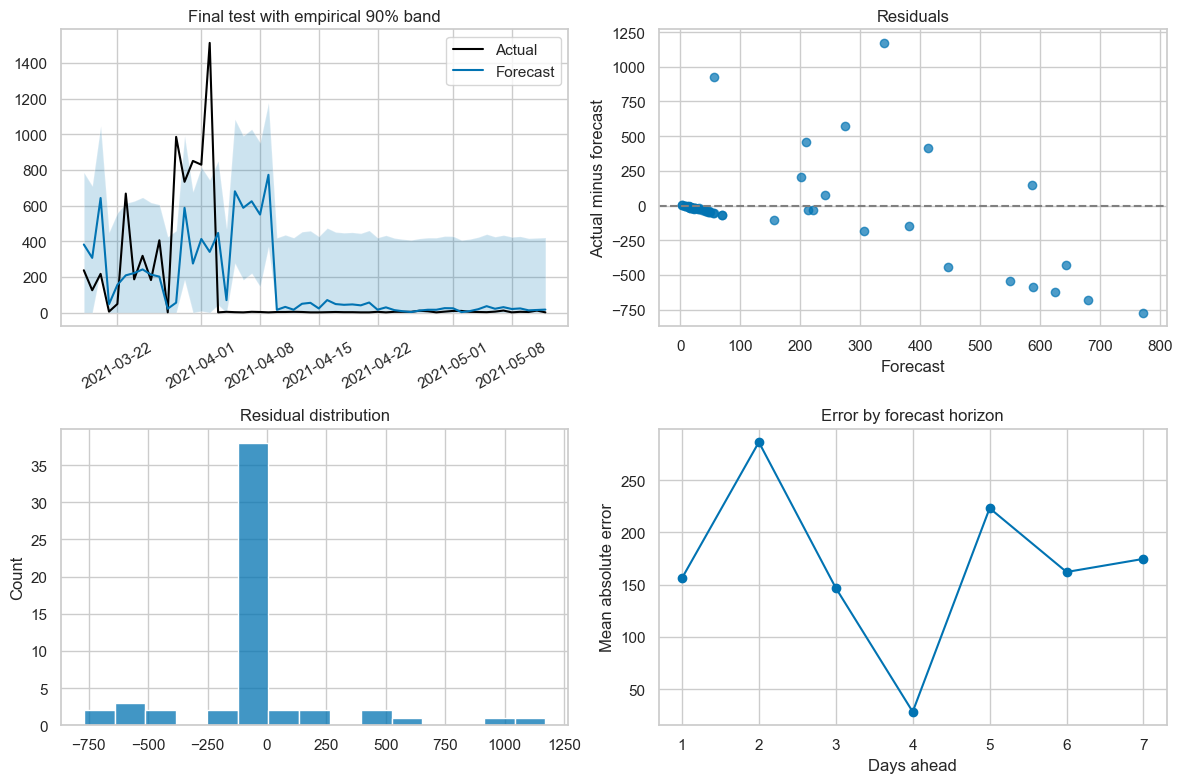

MAPE excludes zero-actual days; zero-day counts are reported. WAPE includes their errors.
A negative R-squared is possible. Do not remove demand collapses or tiny-count days to improve scores.


In [29]:
residuals = overall_test["actual"] - overall_test["prediction"]
coverage = overall_test["actual"].between(overall_test["lower"], overall_test["upper"]).mean()
print(f"Measured test coverage of empirical 90% intervals: {coverage:.1%}")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(overall_test["date"], overall_test["actual"], label="Actual", color="black")
axes[0, 0].plot(overall_test["date"], overall_test["prediction"], label="Forecast")
axes[0, 0].fill_between(overall_test["date"], overall_test["lower"], overall_test["upper"], alpha=0.2)
axes[0, 0].set_title("Final test with empirical 90% band")
axes[0, 0].tick_params(axis="x", rotation=30)
axes[0, 0].legend()
axes[0, 1].scatter(overall_test["prediction"], residuals, alpha=0.7)
axes[0, 1].axhline(0, color="gray", linestyle="--")
axes[0, 1].set(xlabel="Forecast", ylabel="Actual minus forecast", title="Residuals")
sns.histplot(residuals, bins=15, ax=axes[1, 0])
axes[1, 0].set_title("Residual distribution")
horizon_errors = overall_test.assign(error=np.abs(residuals)).groupby("days_ahead")["error"].mean()
axes[1, 1].plot(horizon_errors.index, horizon_errors, "o-")
axes[1, 1].set(xlabel="Days ahead", ylabel="Mean absolute error", title="Error by forecast horizon")
plt.tight_layout()
plt.savefig(reports_folder / "forecast_charts.png", dpi=150)
plt.show()

print("MAPE excludes zero-actual days; zero-day counts are reported. WAPE includes their errors.")
print("A negative R-squared is possible. Do not remove demand collapses or tiny-count days to improve scores.")

**Code explanation:** The overall point forecast equals the sum of specialty forecasts, including Unknown. Overall interval width comes from overall residuals, not a sum of specialty widths.

**Expected output:** Actual forecast scores, baseline comparison, interval coverage, and error charts.

**Validation:** Totals must reconcile to source counts and predictions must remain finite and nonnegative.

**Professional insight:** If demand shifts sharply, explain the observed failure and collect closure/capacity information for a future version. Do not retune on this test period.

## 19. Save the models and use the separate Streamlit app

**Objective:** Make the work usable without a complex application architecture.

**Workflow:** Save two small bundles and seven-day forecasts, check reloading, then run the separate app.py.

In [30]:
category_choices = {}
for column in category_columns:
    category_choices[column] = sorted(X_train[column].fillna("Unknown").unique().tolist())

classifier_bundle = {
    "model": best_classifier,
    "probability_adjustment": probability_adjustment,
    "threshold": decision_threshold,
    "columns": X.columns.tolist(),
    "binary_columns": binary_columns,
    "category_choices": category_choices,
    "last_date": str(daily_counts.index[-1].date()),
}
joblib.dump(classifier_bundle, models_folder / "no_show_model.joblib")

forecast_models = {}
future_rows = []
future_dates = pd.date_range(daily_counts.index[-1] + pd.Timedelta(days=1), periods=7)
for specialty in specialty_counts:
    model, prediction = fit_forecast(specialty_counts[specialty], best_methods[specialty], days=7)
    forecast_models[specialty] = model
    for date, count in zip(future_dates, prediction):
        future_rows.append({"date": date, "specialty": specialty, "prediction": count})
forecast_bundle = {
    "models": forecast_models, "methods": best_methods,
    "history": specialty_counts, "widths": interval_widths,
    "overall_width": overall_interval_width,
    "last_date": str(daily_counts.index[-1].date()), "max_days": 7,
}
joblib.dump(forecast_bundle, models_folder / "demand_model.joblib")
future_predictions = pd.DataFrame(future_rows)
future_predictions.to_csv(reports_folder / "future_specialty_forecasts.csv", index=False)
print("Saved both model bundles. Forecast models use all history only after evaluation.")

Saved both model bundles. Forecast models use all history only after evaluation.


In [31]:
loaded_classifier = joblib.load(models_folder / "no_show_model.joblib")
loaded_forecast = joblib.load(models_folder / "demand_model.joblib")
sample_input = X_test.iloc[[0]]
np.testing.assert_allclose(loaded_classifier["model"].predict_proba(sample_input),
                           best_classifier.predict_proba(sample_input))
assert set(loaded_forecast["models"]) == set(specialty_counts.columns)

prediction_times = []
for _ in range(5):
    start = time.perf_counter()
    raw_probability = loaded_classifier["model"].predict_proba(sample_input)[:, [1]]
    loaded_classifier["probability_adjustment"].predict_proba(raw_probability)
    prediction_times.append(time.perf_counter() - start)
print("Median warm classifier prediction time:", round(float(np.median(prediction_times)), 4), "seconds")
print("Serialization checks passed.")
print("From this project folder, run: python -m streamlit run app.py")

Median warm classifier prediction time: 0.0014 seconds
Serialization checks passed.
From this project folder, run: python -m streamlit run app.py


**Application:** `app.py` is delivered separately. It contains simple Streamlit
tabs for appointment risk and specialty demand, loads the two saved bundles,
and repeats the same small feature calculations explicitly. There is no
`project_utils.py` dependency and the notebook does not generate Python files.

The forecast is anchored to the historical data's last date, not to today's
date. In Colab, download `models/`, `reports/`, `app.py`, and requirements to run
Streamlit locally. A notebook runtime does not automatically host the app.

**Code explanation:** The classifier bundle preserves the frozen evaluated model, adjustment, and threshold. Forecast choices are refitted on all observed history only after evaluation for subsequent dates.

**Expected output:** Two saved bundles and actual warm classifier latency, plus run instructions.

**Validation:** Reloaded classifier probabilities must match; only load trusted joblib files. Check forecast/application latency when running the app.

**Professional insight:** End-to-end application startup, chart rendering, and model inference have different costs. The app measures forecast and risk calculation times separately.

## 20. Report target status and business recommendations

**Objective:** Present results that can be defended in an interview or project review.

**Workflow:** Compare actual test scores with strict goals, quantify a contact-budget scenario, and record limitations.

In [32]:
target_status = pd.DataFrame([
    ["No-show F1", "> 0.70", final_classifier_scores["F1"], final_classifier_scores["F1"] > classification_goals["F1"]],
    ["ROC-AUC", "> 0.75", final_classifier_scores["ROC_AUC"], final_classifier_scores["ROC_AUC"] > classification_goals["ROC_AUC"]],
    ["Overall MAPE (%)", "< 20", final_forecast_scores["MAPE_percent"], final_forecast_scores["MAPE_percent"] < forecast_goals["MAPE_percent"]],
    ["Overall R-squared", "> 0.65", final_forecast_scores["R2"], final_forecast_scores["R2"] > forecast_goals["R2"]],
], columns=["Metric", "Required", "Actual", "Target_met"])
display(target_status.round(4))
target_status.to_csv(reports_folder / "target_status.csv", index=False)
print("All four targets achieved:", bool(target_status["Target_met"].all()))
print("If a goal is missed, report it honestly; this table is not edited manually.")

,Metric,Required,Actual,Target_met
0,No-show F1,> 0.70,0.5171,False
1,ROC-AUC,> 0.75,0.6837,False
2,Overall MAPE (%),< 20,5276.0756,False
3,Overall R-squared,> 0.65,-0.0915,False


All four targets achieved: False
If a goal is missed, report it honestly; this table is not edited manually.


In [33]:
# Ranking scenario only: this does not measure an intervention's effectiveness.
contact_count = max(1, int(np.ceil(0.10 * len(y_test))))
top_positions = np.argsort(-test_probabilities)[:contact_count]
observed_missed = int(y_test.iloc[top_positions].sum())
contact_scenario = pd.DataFrame([{
    "Contact_budget_percent": 10,
    "Appointments_prioritized": contact_count,
    "Observed_no_shows_in_group": observed_missed,
    "Group_no_show_rate": observed_missed / contact_count,
    "Fraction_of_test_no_shows_captured": observed_missed / y_test.sum(),
}])
display(contact_scenario.round(3))
contact_scenario.to_csv(reports_folder / "contact_scenario.csv", index=False)

recommendations = (
    "Use the measured test tables and baseline comparisons when presenting this project.\n"
    "Prioritizing high-risk appointments is a ranking scenario, not proof that reminders reduce no-shows.\n"
    "Pilot any intervention and measure its actual effect and cost.\n"
    "Use forecast error bands and measured coverage when reviewing staffing scenarios.\n"
    "Staffing savings require appointment durations, specialist capacity, shift constraints, and costs.\n"
    "Verify location labels, the continuous-calendar mapping, age flags, and unclear source codes.\n"
    "Collect appointment and patient IDs, booking/cancellation/reminder timestamps, closures, capacity, and forecast weather.\n"
    "Keep failed targets visible. A future model revision needs a new held-out evaluation period.\n"
)
(reports_folder / "recommendations.txt").write_text(recommendations)
print("Reports and recommendations saved. The project can now be reviewed and explained.")

,Contact_budget_percent,Appointments_prioritized,Observed_no_shows_in_group,Group_no_show_rate,Fraction_of_test_no_shows_captured
0,10,1160,692,0.597,0.192


Reports and recommendations saved. The project can now be reviewed and explained.


**Code explanation:** Every status comes from actual test predictions. The contact-budget calculation measures concentration of observed no-shows, not prevented no-shows.

**Expected output:** A truthful pass/fail table and a clearly labeled hypothetical operational scenario.

**Validation:** No numerical score is typed in manually or copied from a previous implementation.

**Professional insight:** A strong fresher project explains its decisions, validates correctly, and reports limitations clearly. Complex code and inflated accuracy do not demonstrate better analytical judgment.

## How to explain this project
1. I separated appointment-level no-show risk from daily booked-demand forecasting.
2. I audited missingness, inconsistent flags, uncertain locations, and the date field.
3. I excluded information that would not be justified at prediction time.
4. I kept entire dates separate for selection, calibration, threshold tuning, and test.
5. I compared three algorithms for each task and retained simple baselines.
6. I used known historical inputs for genuine seven-day forecast blocks.
7. I showed real test scores, uncertainty, and practical limits before suggesting action.

**Style:** Explain what each cell does and why its decisions are appropriate.
The code is intentionally direct, while evaluation remains careful. Simpler
syntax alone does not guarantee better predictions.